In [1]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Display dataset
df = pd.DataFrame(X, columns=iris.feature_names)
df['Target'] = y

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [4]:
# 1. Bagging Classifier
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=50,
    random_state=42
)

bagging.fit(X_train, y_train)
bagging_pred = bagging.predict(X_test)

# 2. Random Forest Classifier
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# 3. AdaBoost Classifier
boosting = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

boosting.fit(X_train, y_train)
boosting_pred = boosting.predict(X_test)

# 4. Voting Classifier
voting = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression(max_iter=1000)),
        ('dt', DecisionTreeClassifier(random_state=42)),
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
    ],
    voting='hard'
)

voting.fit(X_train, y_train)
voting_pred = voting.predict(X_test)

In [5]:
results = {
    "Bagging": accuracy_score(y_test, bagging_pred),
    "Random Forest": accuracy_score(y_test, rf_pred),
    "AdaBoost": accuracy_score(y_test, boosting_pred),
    "Voting Classifier": accuracy_score(y_test, voting_pred)
}

print("Ensemble Techniques Accuracy:\n")

for model, accuracy in results.items():
    print(f"{model}: {accuracy * 100:.2f}%")

Ensemble Techniques Accuracy:

Bagging: 96.67%
Random Forest: 90.00%
AdaBoost: 93.33%
Voting Classifier: 93.33%


In [6]:
print("Classification Report - Random Forest\n")

print(classification_report(
    y_test,
    rf_pred,
    target_names=iris.target_names
))

Classification Report - Random Forest

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



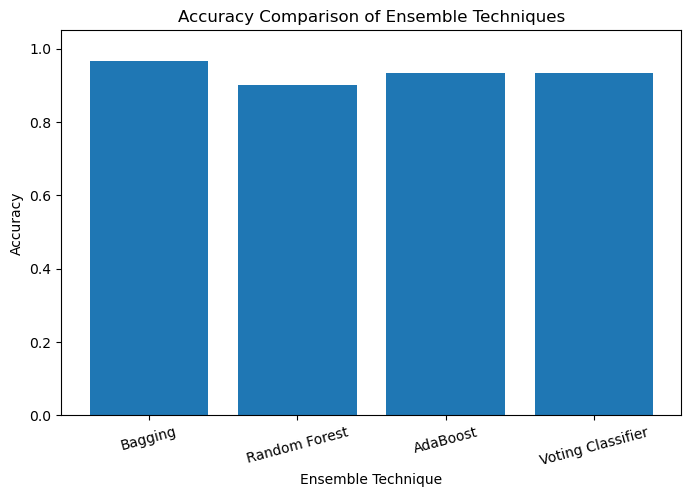

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

plt.title("Accuracy Comparison of Ensemble Techniques")
plt.xlabel("Ensemble Technique")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)

plt.show()